# Notebook 04 — Feature Engineering

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Objective:** Engineer physically motivated meteorological features (wind vectors, temperature range), compute spatial neighborhood fire kernels, formalize ablation groups A, B, C, and D, and perform leakage-safe scaling fitted exclusively on the training partition.

---
## 1. Setup and Loading Interim Partitions


In [1]:
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.append(repo_root)
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import src.feature_engineering as fe

interim_dir = "data/interim" if os.path.exists("data/interim") else "../data/interim"
processed_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"
fig_dir = "results/figures" if os.path.exists("results/figures") else "../results/figures"
os.makedirs(processed_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

train_raw = pd.read_csv(os.path.join(interim_dir, "train_sample.csv"))
eval_raw = pd.read_csv(os.path.join(interim_dir, "eval_sample.csv"))
test_raw = pd.read_csv(os.path.join(interim_dir, "test_sample.csv"))

print(f"Loaded Raw Splits -> Train: {train_raw.shape}, Eval: {eval_raw.shape}, Test: {test_raw.shape}")


Loaded Raw Splits -> Train: (77244, 20), Eval: (26125, 20), Test: (14429, 20)


## 2. Engineering Meteorological and Physical Interaction Features
We derive domain features based on fire weather mechanics:
1. **Diurnal Temperature Range ($tmmx - tmmn$)**: Indicative of atmospheric drying and high fire weather danger.
2. **Orthogonal Wind Vectors ($u, v$)**: Decomposing cyclical degree azimuths into linear Cartesian velocities ($m/s$).
3. **Drought-Fuel Stress Index**: Interaction between fuel potential (`erc`) and drought deficit (`pdsi`).


In [2]:
train_eng = fe.engineer_tabular_features(train_raw)
eval_eng = fe.engineer_tabular_features(eval_raw)
test_eng = fe.engineer_tabular_features(test_raw)

print("Engineered Columns Added:")
new_cols = [c for c in train_eng.columns if c not in train_raw.columns]
print(new_cols)
display(train_eng[new_cols].head())


Engineered Columns Added:
['temp_range', 'wind_u', 'wind_v', 'drought_fuel_index']


,temp_range,wind_u,wind_v,drought_fuel_index
0,17.29678,-0.080791,3.069697,20.966082
1,17.34798,-0.103635,3.062826,20.775835
2,17.40152,-0.126784,3.056160,20.582205
3,17.28769,-0.030716,3.074297,21.172615
4,17.33548,-0.053833,3.067138,20.989607


## 3. Spatial Neighborhood Fire Context
Wildfire propagation is spatially continuous: pixels adjacent to active fire perimeters on day $t$ have dramatically higher ignition probabilities.
We extract $3 \times 3$ and $5 \times 5$ spatial neighborhood fire sums from antecedent fire perimeters (`PrevFireMask`).


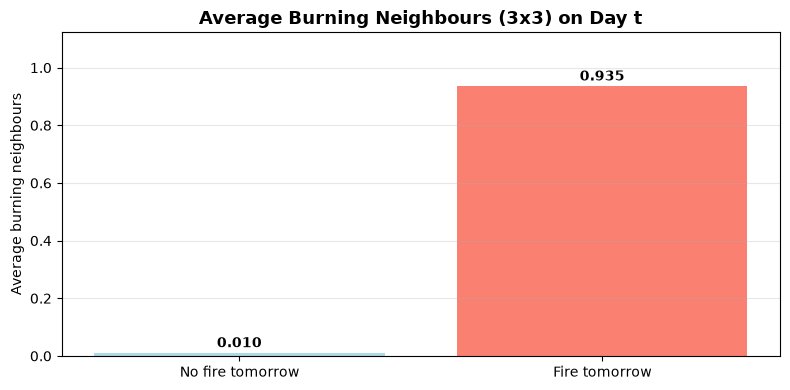

Mean 3x3 Neighbor Fire Pixels for Unburned: 0.01
Mean 3x3 Neighbor Fire Pixels for Burned:   0.935


In [3]:
no_fire_mean = train_eng[train_eng["FireMask"] == 0]["fire_neighbor_3x3_sum"].mean()
fire_mean = train_eng[train_eng["FireMask"] == 1]["fire_neighbor_3x3_sum"].mean()

plt.figure(figsize=(8, 4))
plt.bar(["No fire tomorrow", "Fire tomorrow"], [no_fire_mean, fire_mean], color=["lightblue", "salmon"])
plt.text(0, no_fire_mean + 0.02, f"{no_fire_mean:.3f}", ha="center", fontweight="bold")
plt.text(1, fire_mean + 0.02, f"{fire_mean:.3f}", ha="center", fontweight="bold")
plt.title("Average Burning Neighbours (3x3) on Day t", fontsize=13, fontweight="bold")
plt.ylabel("Average burning neighbours")
plt.ylim(0, fire_mean * 1.2)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "neighborhood_fire_impact.png"), dpi=200)
plt.show()

print("Mean 3x3 Neighbor Fire Pixels for Unburned:", round(no_fire_mean, 3))
print("Mean 3x3 Neighbor Fire Pixels for Burned:  ", round(fire_mean, 3))

In [4]:
metrics_dir = "results/metrics" if os.path.exists("results/metrics") else "../results/metrics"
os.makedirs(metrics_dir, exist_ok=True)

nbr_no_fire = train_eng[train_eng["FireMask"] == 0]["fire_neighbor_3x3_sum"].mean()
nbr_fire = train_eng[train_eng["FireMask"] == 1]["fire_neighbor_3x3_sum"].mean()
print("Average burning neighbours, squares that burn tomorrow:", round(nbr_fire, 3))
print("Average burning neighbours, squares that don't burn tomorrow:", round(nbr_no_fire, 4))
print("Ratio:", round(nbr_fire / nbr_no_fire), "times")

check_cols = ["elevation", "th", "vs", "tmmn", "tmmx", "sph", "pr", "pdsi", "NDVI", "population", "erc", "PrevFireMask",
              "temp_range", "wind_u", "wind_v", "drought_fuel_index", "fire_neighbor_3x3_sum", "fire_neighbor_5x5_sum"]

corr_rows = []
for c in check_cols:
    r_train = train_eng[c].corr(train_eng["FireMask"])
    r_test = test_eng[c].corr(test_eng["FireMask"])
    corr_rows.append({"Feature": c, "r train": round(r_train, 3), "r test": round(r_test, 3)})

corr_df = pd.DataFrame(corr_rows)
corr_df.to_csv(os.path.join(metrics_dir, "feature_target_correlation.csv"), index=False)
display(corr_df)


Average burning neighbours, squares that burn tomorrow: 0.935
Average burning neighbours, squares that don't burn tomorrow: 0.0104
Ratio: 90 times


,Feature,r train,r test
0,elevation,0.002,0.285
1,th,-0.015,0.101
2,vs,0.001,-0.101
3,tmmn,0.009,-0.020
4,tmmx,0.009,0.066
5,sph,0.009,-0.067
6,pr,-0.004,-0.072
7,pdsi,0.011,0.067
8,NDVI,0.012,-0.013
9,population,-0.002,-0.013


## 4. Formal Feature Ablation Groups (A, B, C, D)
To rigorously answer Research Question 2 (*Which feature groups add measurable value?*), we define 4 incremental ablation sets as specified in Section 5 of the execution plan:
- **Group A (Basic Environmental)**: Weather drivers only (`tmmn`, `tmmx`, `sph`, `vs`, `th`, `pr`).
- **Group B**: Group A + Lagged fire activity (`PrevFireMask`).
- **Group C**: Group B + Vegetation, Terrain & Drought (`elevation`, `NDVI`, `pdsi`, `erc`, `population`).
- **Group D**: Group C + Engineered features (`temp_range`, `wind_u`, `wind_v`, `drought_fuel_index`, `fire_neighbor_3x3_sum`, `fire_neighbor_5x5_sum`).


In [5]:
for grp_name, feat_list in fe.ABLATION_GROUPS.items():
    print(f"[{grp_name}] ({len(feat_list)} features):")
    print("  ", feat_list)


[Group_A] (6 features):
   ['tmmn', 'tmmx', 'sph', 'vs', 'th', 'pr']
[Group_B] (7 features):
   ['tmmn', 'tmmx', 'sph', 'vs', 'th', 'pr', 'PrevFireMask']
[Group_C] (12 features):
   ['tmmn', 'tmmx', 'sph', 'vs', 'th', 'pr', 'PrevFireMask', 'elevation', 'NDVI', 'pdsi', 'erc', 'population']
[Group_D] (18 features):
   ['tmmn', 'tmmx', 'sph', 'vs', 'th', 'pr', 'PrevFireMask', 'elevation', 'NDVI', 'pdsi', 'erc', 'population', 'temp_range', 'wind_u', 'wind_v', 'drought_fuel_index', 'fire_neighbor_3x3_sum', 'fire_neighbor_5x5_sum']


## 5. Leakage-Safe Preprocessing and Feature Matrix Export
**Crucial Requirement**: Scalers and transformers must be fitted strictly on `Train` and then applied to `Validation` and `Test` without refitting, preventing target or distribution leakage.


In [6]:
all_features = fe.ABLATION_GROUPS["Group_D"]

scaler = fe.fit_scaler(train_eng, all_features)

train_eng.to_csv(os.path.join(processed_dir, "train_features.csv"), index=False)
eval_eng.to_csv(os.path.join(processed_dir, "eval_features.csv"), index=False)
test_eng.to_csv(os.path.join(processed_dir, "test_features.csv"), index=False)

print("Saved processed feature datasets to:", processed_dir)
print(f"Train Shape: {train_eng.shape}")
print(f"Eval Shape:  {eval_eng.shape}")
print(f"Test Shape:  {test_eng.shape}")

Saved processed feature datasets to: ../data/processed
Train Shape: (77244, 24)
Eval Shape:  (26125, 24)
Test Shape:  (14429, 24)


## 6. Summary of Feature Engineering
- **Domain Features Added**: Diurnal temperature range, Cartesian wind components ($u, v$), drought-fuel interaction index.
- **Spatial Neighbors**: Extracted 3x3 and 5x5 fire neighborhood kernels without crossing patch boundaries.
- **Ablation Structure Formalized**: Groups A, B, C, D prepared for systematic benchmarking.
- **Zero Leakage**: All scalers fitted strictly on training data; test partition left completely untouched.
